In [107]:
!pip install tensorflow keras numpy pandas matplotlib seaborn scikit-learn ipython imagehash pillow rembg onnxruntime opencv-python

In [108]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import backend as K
from tensorflow.keras.layers import Dense, Activation,Dropout,Conv2D, MaxPooling2D,BatchNormalization,Input, GlobalAveragePooling2D, GlobalMaxPooling2D, Layer
from tensorflow.keras.optimizers import Adam, Adamax
from tensorflow.keras.metrics import categorical_crossentropy
from tensorflow.keras import regularizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Model, load_model, Sequential
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG19
from tensorflow.keras.applications.vgg19 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from keras.callbacks import ModelCheckpoint
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from matplotlib.pyplot import imshow
import os
import seaborn as sns
sns.set_style('darkgrid')
from sklearn.metrics import confusion_matrix, classification_report
from IPython.display import display, HTML
import random
import imagehash
from PIL import Image, ImageEnhance
import cv2
import time
from tqdm import tqdm
from sklearn.ensemble import IsolationForest
from sklearn.decomposition import PCA
import shutil
from pathlib import Path
from rembg import remove, new_session

#Load Data

In [109]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [110]:
data_dir = '/content/drive/MyDrive/SKRIPSI/Skenario 1&2/augmentasi/train'

In [111]:
img_size = (224,224)

In [112]:
# Load training dataset dari folder augmented
train_ds = tf.keras.utils.image_dataset_from_directory(
    '/content/drive/MyDrive/SKRIPSI/Skenario 1&2/augmentasi/train',
    labels='inferred',
    label_mode='int',
    image_size=img_size,
    shuffle=True
)

# Load validation dataset dari preprocessed val folder
val_ds = tf.keras.utils.image_dataset_from_directory(
    '/content/drive/MyDrive/SKRIPSI/Skenario 1&2/Data_Split/val',
    labels='inferred',
    label_mode='int',
    image_size=img_size,
    shuffle=False
)

# Load testing dataset dari preprocessed test folder
test_ds = tf.keras.utils.image_dataset_from_directory(
    '/content/drive/MyDrive/SKRIPSI/Skenario 1&2/Data_Split/test',
    labels='inferred',
    label_mode='int',
    image_size=img_size,
    shuffle=False,
    seed=42
)

Found 2091 files belonging to 2 classes.
Found 87 files belonging to 2 classes.
Found 88 files belonging to 2 classes.


In [113]:
AUTOTUNE = tf.data.AUTOTUNE

In [114]:
def rescale(image, label):
    image = preprocess_input(image)
    return image, label

In [115]:
# Terapkan rescale dan prefetch
train_ds = train_ds.map(rescale).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.map(rescale).prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.map(rescale).prefetch(buffer_size=AUTOTUNE)

#Membangun Model

In [116]:
base_model = VGG19(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
# base_model.trainable = False # Freeze base model

In [117]:
# fine-tuning pada block terakhir
for layer in base_model.layers[:-4]:
    layer.trainable = False

for layer in base_model.layers[-4:]:
    layer.trainable = True

In [118]:
# Feature extraction
x = base_model.output

# Feature extraction
x = GlobalAveragePooling2D()(x)
x = Dense(512, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.5)(x)

# Binary classification (2 kelas)
output = Dense(1, activation='sigmoid')(x)

model = Model(inputs=base_model.input, outputs=output)


In [119]:
model.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 20,289,601 (77.40 MB)

 Trainable params: 7,343,617 (28.01 MB)

 Non-trainable params: 12,945,984 (49.39 MB)

#Training

In [120]:
from sklearn.utils.class_weight import compute_class_weight

lr = 0.0001
epochs = 30

print(f"\nTraining dengan learning rate: {lr}")

optimizer = Adam(learning_rate=lr)

model.compile(
    optimizer=optimizer,
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Menghitung bobot kelas dari train_ds...")
y_train_labels = np.concatenate([y.numpy() for _, y in train_ds], axis=0)

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_labels),
    y=y_train_labels
)
bobot_kelas = dict(enumerate(class_weights))
print(f"Bobot kelas yang diterapkan: {bobot_kelas}")

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

start_time = time.time()

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1,
    class_weight=bobot_kelas
)

end_time = time.time()
training_time = end_time - start_time

def evaluate_dataset(ds, model):
    y_true = np.concatenate([y.numpy() for _, y in ds], axis=0)
    y_pred_probs = model.predict(ds, verbose=0).flatten()
    y_pred = (y_pred_probs > 0.5).astype(int)
    return y_true, y_pred, y_pred_probs

y_true_train, y_pred_train, y_prob_train = evaluate_dataset(train_ds, model)
y_true_val, y_pred_val, y_prob_val = evaluate_dataset(val_ds, model)

best_epoch = np.argmin(history.history['val_loss']) + 1

print("\nTraining selesai")
print(f"Learning rate  : {lr}")
print(f"Best epoch     : {best_epoch}")
print(f"Waktu training : {training_time:.2f} detik")


Training dengan learning rate: 0.0001
Menghitung bobot kelas dari train_ds...
Bobot kelas yang diterapkan: {0: np.float64(1.405241935483871), 1: np.float64(0.7761692650334076)}
Epoch 1/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 28s 332ms/step - accuracy: 0.8503 - loss: 0.3722 - val_accuracy: 0.8736 - val_loss: 0.4145
Epoch 2/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 18s 269ms/step - accuracy: 0.9096 - loss: 0.2433 - val_accuracy: 0.8621 - val_loss: 0.5097
Epoch 3/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 17s 259ms/step - accuracy: 0.9350 - loss: 0.1866 - val_accuracy: 0.9080 - val_loss: 0.3356
Epoch 4/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 17s 259ms/step - accuracy: 0.9622 - loss: 0.0940 - val_accuracy: 0.9195 - val_loss: 0.3561
Epoch 5/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 18s 268ms/step - accuracy: 0.9857 - loss: 0.0464 - val_accuracy: 0.9195 - val_loss: 0.3861
Epoch 6/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 18s 267ms/step - accuracy: 0.9818 - loss: 0.0555 - val_accuracy: 0.9195 - val_loss: 0.3919
Epoch 7/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 20s 260ms/

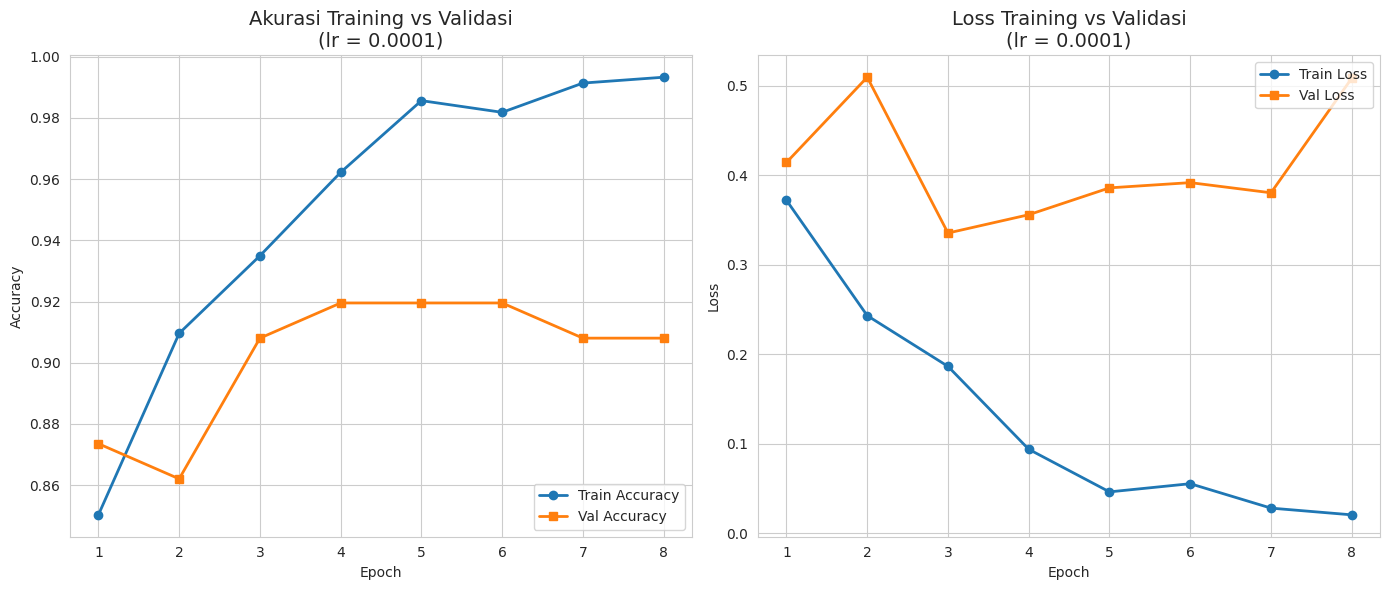

In [121]:
def plot_history(history, lr):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']

    epochs_range = range(1, len(acc) + 1)

    # Gunakan style seaborn
    sns.set_style("whitegrid")
    plt.figure(figsize=(14, 6))

    # Plot Akurasi
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, marker='o', label='Train Accuracy', linewidth=2)
    plt.plot(epochs_range, val_acc, marker='s', label='Val Accuracy', linewidth=2)
    plt.title(f'Akurasi Training vs Validasi\n(lr = {lr})', fontsize=14)
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')
    plt.grid(True)

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, marker='o', label='Train Loss', linewidth=2)
    plt.plot(epochs_range, val_loss, marker='s', label='Val Loss', linewidth=2)
    plt.title(f'Loss Training vs Validasi\n(lr = {lr})', fontsize=14)
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')
    plt.grid(True)

    plt.tight_layout()
    plt.show()

# History plot
plot_history(history, lr)

#Simpan Best Model

In [122]:
save_dir = '/content/drive/MyDrive/SKRIPSI/Skenario 1&2/best model skenario 2'
os.makedirs(save_dir, exist_ok=True)  # Buat folder jika belum ada

save_path = os.path.join(save_dir, 'best_model2.h5')

# Simpan model terbaik (sudah otomatis best karena EarlyStopping restore_best_weights=True)
model.save(save_path)

print(f"Model terbaik berhasil disimpan ke: {save_path}")


Model terbaik berhasil disimpan ke: /content/drive/MyDrive/SKRIPSI/Skenario 1&2/best model skenario 2/best_model2.h5


#Testing

Load Data Testing

In [123]:
from tensorflow.keras.models import load_model

model_path = "/content/drive/MyDrive/SKRIPSI/Skenario 1&2/best model skenario 2/best_model2.h5"

best_model_loaded = load_model(model_path)

print(f"Model berhasil dimuat dari: {model_path}")



Model berhasil dimuat dari: /content/drive/MyDrive/SKRIPSI/Skenario 1&2/best model skenario 2/best_model2.h5


In [124]:
best_model_loaded.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 20,289,603 (77.40 MB)

 Trainable params: 7,343,617 (28.01 MB)

 Non-trainable params: 12,945,984 (49.39 MB)

 Optimizer params: 2 (12.00 B)

In [125]:
def run_test(model, test_ds):
    start_time = time.time()

    y_pred_probs = model.predict(test_ds).flatten()
    y_pred = (y_pred_probs > 0.5).astype(int)
    y_true = np.concatenate([y.numpy() for _, y in test_ds], axis=0)

    end_time = time.time()
    print(f"Waktu inferensi: {end_time - start_time:.2f} detik")

    return y_true, y_pred, y_pred_probs

In [126]:
y_true_test, y_pred_test, y_probs_test = run_test(best_model_loaded, test_ds)

3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 543ms/step
Waktu inferensi: 3.05 detik


=== Classification Report ===
              precision    recall  f1-score   support

  Lumpy Skin       0.93      0.84      0.88        31
 Normal Skin       0.92      0.96      0.94        57

    accuracy                           0.92        88
   macro avg       0.92      0.90      0.91        88
weighted avg       0.92      0.92      0.92        88

=== Confusion Matrix ===


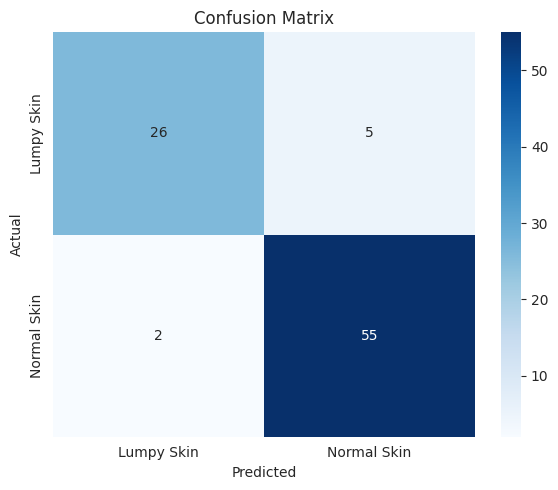

In [127]:
def evaluate_test_results(y_true, y_pred, y_pred_probs):
    print("=== Classification Report ===")
    print(classification_report(y_true, y_pred, target_names=['Lumpy Skin', 'Normal Skin']))

    print("=== Confusion Matrix ===")
    cm = confusion_matrix(y_true, y_pred)
    labels = ['Lumpy Skin', 'Normal Skin']
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix')
    plt.tight_layout()
    plt.show()

evaluate_test_results(y_true_test, y_pred_test, y_probs_test)

In [128]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

acc = accuracy_score(y_true_test, y_pred_test)
prec = precision_score(y_true_test, y_pred_test)
rec = recall_score(y_true_test, y_pred_test)
f1 = f1_score(y_true_test, y_pred_test)

print("=== Ringkasan Evaluasi Test Set ===")
print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-score  : {f1:.4f}")

=== Ringkasan Evaluasi Test Set ===
Accuracy  : 0.9205
Precision : 0.9167
Recall    : 0.9649
F1-score  : 0.9402


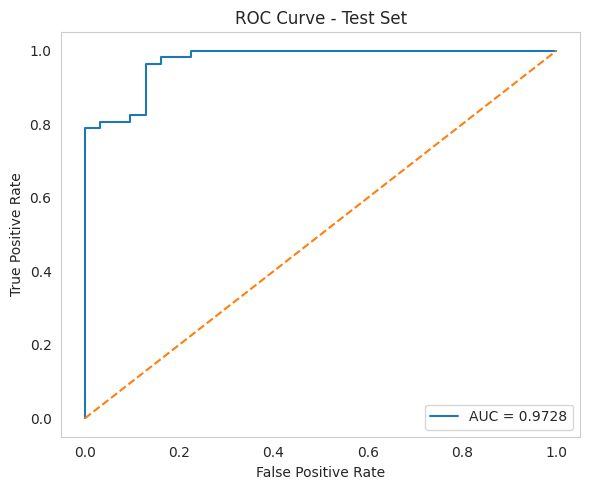

Nilai AUC: 0.9728


In [129]:
from sklearn.metrics import roc_curve, auc

def plot_roc_curve(y_true, y_probs):
    fpr, tpr, _ = roc_curve(y_true, y_probs)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.4f}')
    plt.plot([0, 1], [0, 1], linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve - Test Set')
    plt.legend(loc='lower right')
    plt.grid()
    plt.tight_layout()
    plt.show()

    print(f"Nilai AUC: {roc_auc:.4f}")

plot_roc_curve(y_true_test, y_probs_test)